In [1]:
from rdkit import Chem
import numpy as np
import csv
import joblib
import sys
sys.path.append('molecule-web-app/backend/rules')  # replace with your local path
sys.path.append('molecule-web-app/backend')
# Now you can import your module as usual
from rules import execute_step
import helper
from ml_helper import make_fingerprint

In [2]:
all_data = []
with open('data/cc_ia.csv', newline='') as csvfile:
    reader = csv.reader(csvfile)
    for row in reader:
        all_data.append(row)

cc_rxns = np.array(all_data)[1 :,3]

In [3]:
clf = joblib.load("xg_model.pkl")

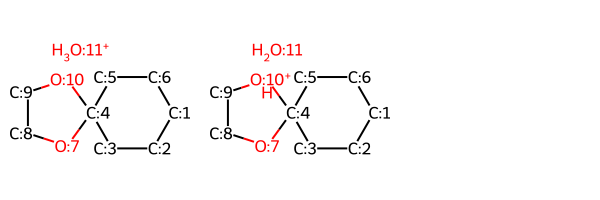

In [13]:
sm_list = []
prod_list = []
for rxn in cc_rxns:
    sm_list.append(Chem.MolFromSmiles(rxn.split('>>')[0]))
    prod_list.append(Chem.MolFromSmiles(rxn.split('>>')[1]))

idx = 90

sm = sm_list[idx]
prod = prod_list[idx]

Chem.SanitizeMol(sm)
Chem.SanitizeMol(prod)
Chem.Draw.MolsToGridImage([sm, prod])

In [18]:
sm_smiles = Chem.MolToSmiles(sm)
prod_smiles = Chem.MolToSmiles(prod)
output = execute_step(sm_smiles, True, True, None, False)
n_output = len(output[0])
smiles_list = []
success_list = []
for i in range(n_output):
    smiles = Chem.MolToSmiles(output[0][i])
    smiles_list.append(smiles)
    fp = make_fingerprint(output[0][i], output[1][i])
    pred = clf.predict(np.array(fp).reshape(1, -1))
    if pred[0] == 1:
        success_list.append(smiles)

if prod_smiles in smiles_list:
    print("Success")
if prod_smiles in success_list:
    print("Double success")

    

Success


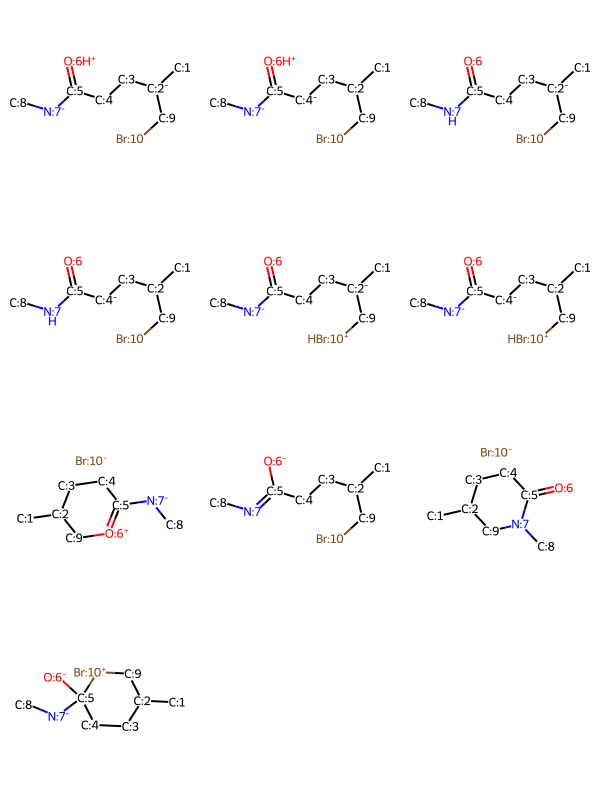

In [19]:
Chem.Draw.MolsToGridImage(output[0])

In [36]:
successes = []
low_successes = []
failures = []
for rxn in cc_rxns:
    sm = Chem.MolFromSmiles(rxn.split('>>')[0])
    prod = Chem.MolFromSmiles(rxn.split('>>')[1])
    for a in sm.GetAtoms():
        a.SetAtomMapNum(0)
    for a in prod.GetAtoms():
        a.SetAtomMapNum(0)
    prod_smiles = Chem.MolToSmiles(prod)
    sm_smiles = Chem.MolToSmiles(sm)
    prod_smiles = Chem.MolToSmiles(prod)
    output = execute_step(sm_smiles, True, True, None, False)
    n_output = len(output[0])
    smiles_list = []
    success_list = []
    for i in range(n_output):
        Chem.SanitizeMol(output[0][i])
        smiles = Chem.MolToSmiles(output[0][i])
        smiles_list.append(smiles)
        fp = make_fingerprint(output[0][i], output[1][i])
        pred = clf.predict(np.array(fp).reshape(1, -1))
        if pred[0] == 1:
            success_list.append(smiles)

    if prod_smiles in smiles_list:
        low_successes.append(rxn)
    else:
        failures.append(rxn)
    if prod_smiles in success_list:
        successes.append(rxn)
    

There will be hydrogen but we will skip for now
There will be hydrogen but we will skip for now
There will be hydrogen but we will skip for now
There will be hydrogen but we will skip for now
There will be hydrogen but we will skip for now
Error in calculating shortest path


[10:57:00] 

****
Invariant Violation

Violation occurred on line 341 in file /project/build/temp.linux-x86_64-cpython-313/rdkit/Code/GraphMol/Matrices.cpp
Failed Expression: aid1 != aid2
----------
Stacktrace:
----------
****



There will be hydrogen but we will skip for now
There will be hydrogen but we will skip for now
There will be hydrogen but we will skip for now
There will be hydrogen but we will skip for now


In [37]:
len(successes)

45

In [38]:
len(low_successes)

97

In [55]:
len(failures)

50

In [56]:
len(cc_rxns)

147

In [98]:
accounted_for = 0
unaccounted_for = []
for idx in range(len(failures)):
    smiles = str(failures[idx]).split('>>')
    sm = Chem.MolFromSmiles(smiles[0])
    for a in sm.GetAtoms():
        a.SetAtomMapNum(0)
    sm_smiles = Chem.MolToSmiles(sm)
    prod = Chem.MolFromSmiles(smiles[1])
    for a in prod.GetAtoms():
        a.SetAtomMapNum(0)
    prod_smiles = Chem.MolToSmiles(prod)
    output = execute_step(sm_smiles, True, True, None, False)
    n_output = len(output[0])
    smiles_list = []
    found = False
    for i in range(n_output):
        Chem.SanitizeMol(output[0][i])
        if output[0][i].HasSubstructMatch(keto_enol) or output[0][i].HasSubstructMatch(double_bond) or output[0][i].HasSubstructMatch(hydroboration):
            accounted_for += 1
            found = True
            break
        smiles_out = Chem.MolToSmiles(output[0][i])
        smiles_list.append(smiles_out)
        fp = make_fingerprint(output[0][i], output[1][i])
        pred = clf.predict(np.array(fp).reshape(1, -1))
    if not found:
        unaccounted_for.append(sm)
print(accounted_for)
#print(smiles_list[9])
#Chem.Draw.MolsToGridImage([sm, prod]+   output[0])

37


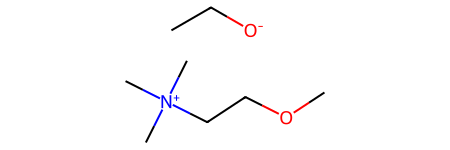

In [112]:
unaccounted_for[12]

SMARTS matching to deal with annoying cases

In [80]:
keto_enol = Chem.MolFromSmarts('[O,N,S;!-]=[*][C-]')
double_bond = Chem.MolFromSmarts('[C+][*-]')
hydroboration = Chem.MolFromSmarts('[C+]C[B-]')

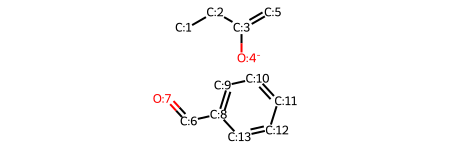

In [ ]:
for failure in failures:
    sm = Chem.MolFromSmiles(failure.split('>>')[0])
    prod = Chem.MolFromSmiles(failure.split('>>')[1])
    if sm.HasSubstructMatch(keto_enol) or sm.HasSubstructMatch(double_bond) or sm.HasSubstructMatch(hydroboration):
        print(failure)
        print(sm.HasSubstructMatch(keto_enol))
        print(sm.HasSubstructMatch(double_bond))
        print(sm.HasSubstructMatch(hydroboration))
        print("")
